# Lohoff Figure 2a recreation with gastrulation-atlas data

Run TissueAgent to recreate the **Gastrulation atlas** and **seqFISH** panels from the authors' published joint UMAP coordinates and cell-type labels. The inputs contain 16,861 atlas cells and 57,536 seqFISH cells; excluding `Low quality` cells leaves 16,861 and 52,568 plotted cells, respectively.

The two CSV files were extracted from [`MGA_joint_UMAP.Rds`](https://content.cruk.cam.ac.uk/jmlab/SpatialMouseAtlas2020/MGA_joint_UMAP.Rds), released with [Lohoff et al.](https://doi.org/10.1038/s41587-021-01006-2). Sources and checksums are recorded in `data/provenance_lohoff-2a.json`. These are **processed coordinates and annotations, not raw atlas expression**; this demo reconstructs the plotting workflow, not the upstream integration or UMAP computation.

The original seqFISH AnnData is retained as additional input. Its `obsm['X_umap']` differs from the published joint embedding, so both panels use the matching CSV coordinates. No color-map file is supplied; any colors estimated from the reference must be documented.


In [1]:
from pathlib import Path
import hashlib
import json
import os
import shutil
import socket
import subprocess
import sys
from datetime import datetime, timezone

from IPython.display import Image, display

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "pyproject.toml").exists():
    REPO_ROOT = REPO_ROOT.parent
assert (REPO_ROOT / "pyproject.toml").exists(), "Run this notebook from demo/ or the repository root."

TASK_NAME = "figure_recreation_lohoff-2a_with_atlas"
TASK_ID = "lohoff_2a_published_joint_atlas_seqfish"
MODEL = "gpt-5.5"
DATA_DIR = REPO_ROOT / "demo/data"
DATASETS = [
    DATA_DIR / "dataset_lohoff_et_al_seqfish.h5ad",
    DATA_DIR / "gastrulation_atlas_joint_umap.csv",
    DATA_DIR / "seqfish_author_joint_umap.csv",
]
REFERENCE = DATA_DIR / "reference_lohoff-2a.png"
ATTACHMENTS = [REFERENCE, DATA_DIR / "instructions_lohoff-2a.md"]
INPUTS = [*DATASETS, *ATTACHMENTS]
OUTPUT_DIR = REPO_ROOT / "demo/outputs" / TASK_NAME
PROMPT = "I have provided the seqFISH dataset dataset_lohoff_et_al_seqfish.h5ad and the matching published gastrulation-atlas data for Lohoff et al. Fig. 2a. The files gastrulation_atlas_joint_umap.csv and seqfish_author_joint_umap.csv contain the authors' joint UMAP coordinates (UMAP1, UMAP2), cell IDs, population, embryo, and cell-type labels. Create a side-by-side UMAP figure with panels titled Gastrulation atlas and seqFISH, colored consistently by cell type and with shared UMAP1 and UMAP2 labeling. A reference image is included in reference_lohoff-2a.png. Make the supported plot content and overall layout as close as possible to the reference.\n\nUse the genuine joint coordinates in BOTH CSVs for this figure. The original demo AnnData is retained as additional seqFISH input, but its obsm['X_umap'] is a different embedding and must not be mixed with the atlas joint coordinates. The author figure excludes cells labeled Low quality; document all exclusions and report the number of plotted cells in each panel. Do not fabricate cells, recompute the supplied embedding, modify individual coordinates to resemble the reference, or paste reference-image pixels into the result. An explicitly documented axis-direction change for visual orientation is acceptable. No color-map file is supplied; document any approximated colors.\n\nSave the recreated figure as PNG and PDF, executable plotting code, the plotted cell-level data, a color map, and a brief reproduction report under the project's outputs directory. Identify the data sources and clarify that this is figure reproduction from published processed coordinates, not a rerun of raw-count integration. Inspect the final figure and verify that both panels contain real supplied cells. Work only from the provided inputs; do not retrieve earlier TissueAgent or baseline reproductions."
PROMPT += ' Save the accepted final figure at outputs/final_figure.png and outputs/final_figure.pdf; these files must contain the requested complete multi-panel figure, not diagnostic plots. Also save executable plotting code, outputs/tables/plotted_data.csv, outputs/tables/colormap.yaml, and outputs/reports/reproduction_report.md. The plotted-data table must contain columns panel, cell, x, y, celltype, with the original input cell identifier, unmodified input coordinates, and original cell-type label for each plotted cell. Record axis inversion in the report, not by changing exported coordinates. Inspect the accepted final PNG against the supplied reference before completing. Never copy reference-image pixels into the generated figure.'
ROLES = {'dataset_lohoff_et_al_seqfish.h5ad': 'seqfish_expression_reference', 'gastrulation_atlas_joint_umap.csv': 'atlas_joint_embedding', 'seqfish_author_joint_umap.csv': 'seqfish_joint_embedding', 'reference_lohoff-2a.png': 'reference', 'instructions_lohoff-2a.md': 'input_notes'}

def input_records():
    records = []
    for path in INPUTS:
        assert path.is_file(), f"Missing input: {path}"
        with path.open("rb") as stream:
            digest = hashlib.file_digest(stream, "sha256").hexdigest()
        records.append({"role": ROLES[path.name], "path": str(path), "name": path.name, "sha256": digest})
    return records

INPUT_RECORDS = input_records()
PROVENANCE = json.loads((DATA_DIR / "provenance_lohoff-2a.json").read_text())
for record in INPUT_RECORDS:
    if record["name"] in PROVENANCE["inputs"]:
        assert record["sha256"] == PROVENANCE["inputs"][record["name"]]["sha256"], record["name"]

print(json.dumps({
    "task": TASK_NAME,
    "datasets": [str(path) for path in DATASETS],
    "attachments": [str(path) for path in ATTACHMENTS],
    "supplied_colormap": False,
    "input_cells": PROVENANCE["input_cells"],
    "expected_plotted_cells": PROVENANCE["non_low_quality_cells"],
    "output_dir": str(OUTPUT_DIR),
}, indent=2))


{
  "task": "figure_recreation_lohoff-2a_with_atlas",
  "datasets": [
    "/Users/wenduoc/new_TissueAgent/TissueAgent/demo/data/dataset_lohoff_et_al_seqfish.h5ad",
    "/Users/wenduoc/new_TissueAgent/TissueAgent/demo/data/gastrulation_atlas_joint_umap.csv",
    "/Users/wenduoc/new_TissueAgent/TissueAgent/demo/data/seqfish_author_joint_umap.csv"
  ],
  "attachments": [
    "/Users/wenduoc/new_TissueAgent/TissueAgent/demo/data/reference_lohoff-2a.png",
    "/Users/wenduoc/new_TissueAgent/TissueAgent/demo/data/instructions_lohoff-2a.md"
  ],
  "supplied_colormap": false,
  "input_cells": {
    "Gastrulation atlas": 16861,
    "seqFISH": 57536
  },
  "expected_plotted_cells": {
    "Gastrulation atlas": 16861,
    "seqFISH": 52568
  },
  "output_dir": "/Users/wenduoc/new_TissueAgent/TissueAgent/demo/outputs/figure_recreation_lohoff-2a_with_atlas"
}


## Run the CLI

The saved outputs show a completed reproduction with the supplied atlas and seqFISH inputs. To execute this cell, set `OPENAI_API_KEY` in the notebook environment. It makes model calls unless a matching completed local run already exists; generated run directories are not bundled with the repository.

The CLI stages all three datasets, writes `transcript.log`, and retains execution state under `OUTPUT_DIR`. A later run reuses a completed local result only when the model, prompt, and input checksums match. Choose a new `OUTPUT_DIR` to rerun with changed inputs or settings.


In [2]:
manifest_path = OUTPUT_DIR / "run_manifest.json"
metrics_path = OUTPUT_DIR / "metrics.json"
if OUTPUT_DIR.is_dir() and manifest_path.is_file() and metrics_path.is_file():
    manifest = json.loads(manifest_path.read_text())
    metrics = json.loads(metrics_path.read_text())
    terminal_state = metrics.get("outcome", {}).get("terminal_state")
    expected_hashes = {record["name"]: record["sha256"] for record in INPUT_RECORDS}
    cached_hashes = {record["name"]: record["sha256"] for record in manifest["inputs"]}
    assert terminal_state == "completed" and manifest.get("cli_exit_code") == 0
    assert manifest.get("supplied_colormap") is False
    assert manifest.get("prompt") == PROMPT, "Prompt changed; choose a new OUTPUT_DIR."
    assert manifest.get("model") == MODEL, "Model changed; choose a new OUTPUT_DIR."
    assert cached_hashes == expected_hashes, "Inputs changed; choose a new OUTPUT_DIR."
    print(json.dumps({
        "terminal_state": terminal_state,
        "elapsed_seconds": manifest["elapsed_seconds"],
        "output_dir": str(OUTPUT_DIR),
        "reused_completed_output": True,
    }, indent=2))
else:
    if OUTPUT_DIR.exists():
        raise RuntimeError(f"{OUTPUT_DIR} already exists. Choose a new OUTPUT_DIR for a fresh run.")
    assert os.environ.get("OPENAI_API_KEY"), "Set OPENAI_API_KEY in the notebook environment for a fresh run."
    OUTPUT_DIR.mkdir(parents=True)
    STATE_ROOT = OUTPUT_DIR / "state"
    with socket.socket() as sock:
        sock.bind(("127.0.0.1", 0))
        gateway_port = sock.getsockname()[1]
    env = os.environ.copy()
    env.update({
        "TISSUEAGENT_STATE_ROOT": str(STATE_ROOT),
        "TISSUEAGENT_GATEWAY_PORT": str(gateway_port),
        "TISSUEAGENT_ORCHESTRATION_REASONING_EFFORT": "medium",
        "TISSUEAGENT_WORKER_REASONING_EFFORT": "high",
        "NUMBA_CACHE_DIR": str(OUTPUT_DIR / "cache/numba"),
        "MPLCONFIGDIR": str(OUTPUT_DIR / "cache/matplotlib"),
        "XDG_CACHE_HOME": str(OUTPUT_DIR / "cache/xdg"),
        "IPYTHONDIR": str(OUTPUT_DIR / "cache/ipython"),
        "JUPYTER_RUNTIME_DIR": str(OUTPUT_DIR / "cache/jupyter_runtime"),
        "PYTHONPATH": str(REPO_ROOT / "src") + os.pathsep + str(REPO_ROOT),
        "PATH": str(Path(sys.executable).parent) + os.pathsep + env.get("PATH", ""),
    })
    for key in ["NUMBA_CACHE_DIR", "MPLCONFIGDIR", "XDG_CACHE_HOME", "IPYTHONDIR", "JUPYTER_RUNTIME_DIR"]:
        Path(env[key]).mkdir(parents=True, exist_ok=True)
    command = [
        sys.executable, "-m", "cli", "--no-docker", "--json", "--model", MODEL,
        "--task-id", TASK_ID, "--seed", "0", "--attempt", "1",
        "--metrics-out", str(metrics_path),
    ]
    for dataset in DATASETS:
        command.extend(["--dataset", str(dataset)])
    for attachment in ATTACHMENTS:
        command.extend(["--attach", str(attachment)])
    command.append("-")

    transcript_path = OUTPUT_DIR / "transcript.log"
    (OUTPUT_DIR / "prompt.txt").write_text(PROMPT + "\n")
    started_at = datetime.now(timezone.utc)
    with transcript_path.open("w") as transcript:
        completed = subprocess.run(
            command, input=PROMPT, cwd=REPO_ROOT, env=env,
            stdout=transcript, stderr=subprocess.STDOUT, text=True, check=False,
        )
    finished_at = datetime.now(timezone.utc)
    project_dir = STATE_ROOT / "workspace/project"
    project_outputs = project_dir / "outputs"
    if project_outputs.is_dir():
        for source in project_outputs.iterdir():
            destination = OUTPUT_DIR / source.name
            if source.is_dir():
                shutil.copytree(source, destination, dirs_exist_ok=True)
            else:
                shutil.copy2(source, destination)
    if (project_dir / "metrics.json").is_file():
        shutil.copy2(project_dir / "metrics.json", OUTPUT_DIR / "project_metrics.json")
    if not metrics_path.is_file():
        raise RuntimeError(f"CLI exited {completed.returncode} without metrics. See {transcript_path}; state retained at {STATE_ROOT}.")
    metrics = json.loads(metrics_path.read_text())
    terminal_state = metrics.get("outcome", {}).get("terminal_state")
    manifest = {
        "task": TASK_NAME, "task_id": TASK_ID, "model": MODEL,
        "started_at_utc": started_at.isoformat(),
        "finished_at_utc": finished_at.isoformat(),
        "elapsed_seconds": metrics.get("run", {}).get("wall_time_s", (finished_at - started_at).total_seconds()),
        "elapsed_seconds_definition": "CLI-reported workflow wall time, falling back to subprocess wall time",
        "command": command, "prompt": PROMPT, "inputs": INPUT_RECORDS,
        "supplied_colormap": False, "cli_exit_code": completed.returncode,
        "terminal_state": terminal_state, "state_root": str(STATE_ROOT),
    }
    manifest_path.write_text(json.dumps(manifest, indent=2) + "\n")
    if completed.returncode != 0 or terminal_state != "completed":
        raise RuntimeError(f"CLI failed (exit={completed.returncode}, terminal_state={terminal_state}). See {transcript_path}; state retained at {STATE_ROOT}.")
    print(json.dumps({"terminal_state": terminal_state, "elapsed_seconds": manifest["elapsed_seconds"], "output_dir": str(OUTPUT_DIR)}, indent=2))


{
  "terminal_state": "completed",
  "elapsed_seconds": 431.17,
  "output_dir": "/Users/wenduoc/new_TissueAgent/TissueAgent/demo/outputs/figure_recreation_lohoff-2a_with_atlas"
}


## Validate the plotted data

Check cell identities, labels, and original coordinates before displaying the final figure.


In [3]:
import numpy as np
import pandas as pd

plotted = pd.read_csv(OUTPUT_DIR / "tables/plotted_data.csv", dtype={"cell": str})
assert {"panel", "cell", "x", "y", "celltype"} <= set(plotted.columns)
expected_sources = {
    "Gastrulation atlas": DATA_DIR / "gastrulation_atlas_joint_umap.csv",
    "seqFISH": DATA_DIR / "seqfish_author_joint_umap.csv",
}
assert set(plotted["panel"]) == set(expected_sources)
for panel, path in expected_sources.items():
    expected = pd.read_csv(path, dtype={"cell": str})
    expected = expected.loc[expected["celltype"] != "Low quality"].set_index("cell").sort_index()
    actual = plotted.loc[plotted["panel"] == panel].set_index("cell").sort_index()
    assert actual.index.is_unique and actual.index.equals(expected.index), panel
    assert actual["celltype"].equals(expected["celltype"]), panel
    np.testing.assert_allclose(actual[["x", "y"]], expected[["UMAP1", "UMAP2"]], rtol=0, atol=1e-10)
assert plotted.groupby("panel").size().to_dict() == {"Gastrulation atlas": 16861, "seqFISH": 52568}
print("Verified original cell IDs, labels, and joint UMAP coordinates; Low quality cells excluded.")
display(plotted.groupby("panel").size().rename("Plotted cells").to_frame())


Verified original cell IDs, labels, and joint UMAP coordinates; Low quality cells excluded.


,Plotted cells
panel,
Gastrulation atlas,16861
seqFISH,52568


## Final figure


demo/outputs/figure_recreation_lohoff-2a_with_atlas/final_figure.png


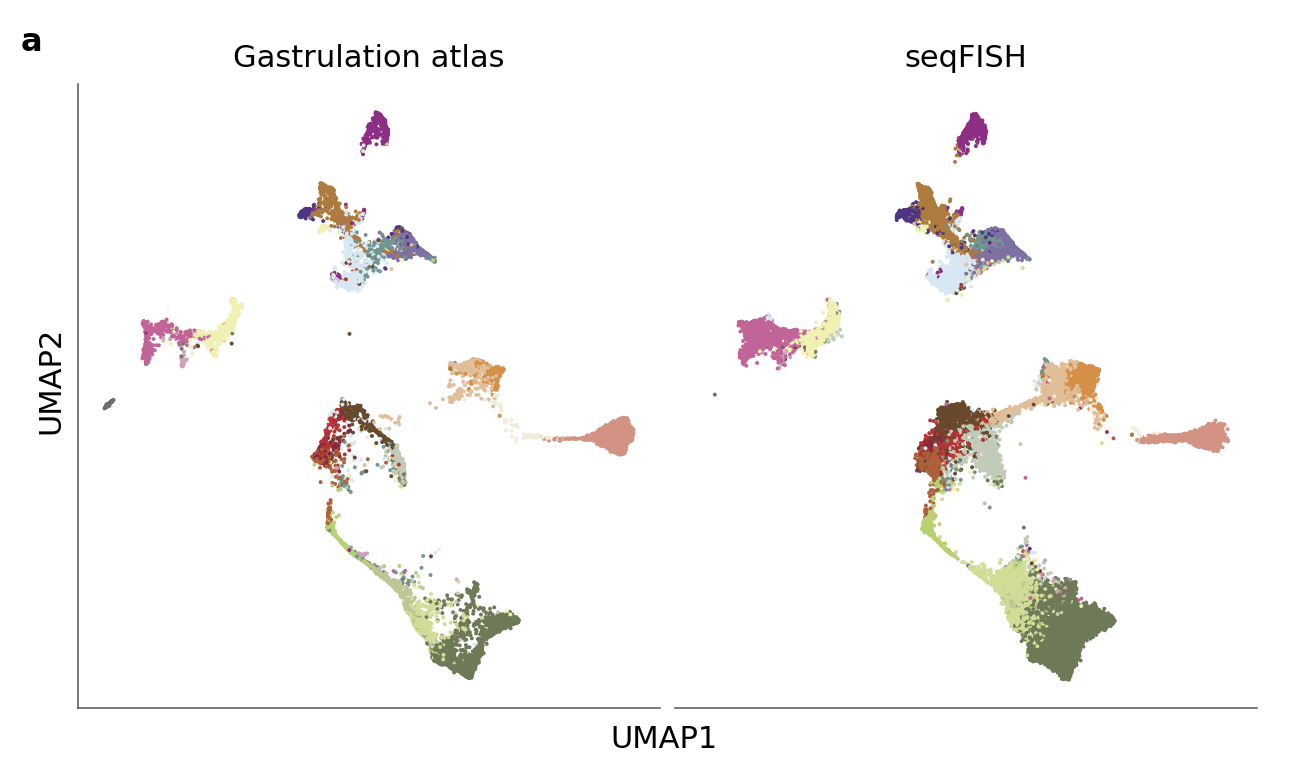

# Lohoff et al. Fig. 2a reproduction report

## Output summary

Accepted final figure files:

- `project/outputs/final_figure.png`
- `project/outputs/final_figure.pdf`

Supporting artifacts:

- Executable plotting code: `project/outputs/plotting_code.py`
- Plotted cell-level data: `project/outputs/tables/plotted_data.csv`
- Color map: `project/outputs/tables/colormap.yaml`
- Comparison metrics: `project/outputs/tables/compare_metrics.json`
- Comparison/diff image: `project/outputs/figures/compare_diff.png`

The accepted figure is attempt 2 (`project/outputs/figures/lohoff_2a_attempt2.png/.pdf`), copied byte-for-byte to the final figure paths.

## Data sources and scope

This is a **figure reproduction from published processed joint UMAP coordinates**, not a rerun of raw-count integration or joint embedding construction.

Plotted data were read from the supplied CSV coordinate tables only:

1. `library/datasets/gastrulation_atlas_joint_umap.csv`
2. `library/datasets/seqfish_author_joint

In [4]:
selected = OUTPUT_DIR / "final_figure.png"
for path in (selected, OUTPUT_DIR / "final_figure.pdf", OUTPUT_DIR / "tables/colormap.yaml",
             OUTPUT_DIR / "reports/reproduction_report.md"):
    assert path.is_file(), f"Missing required final artifact: {path}. Inspect transcript.log; diagnostics are not final figures."
print(selected.relative_to(REPO_ROOT))
display(Image(filename=str(selected)))
print((OUTPUT_DIR / "reports/reproduction_report.md").read_text())
